In [ ]:
import random
import time
import matplotlib.pyplot as plt


In [ ]:
class Student:
    def __init__(self, roll, name, marks):
        self.roll = roll
        self.name = name
        self.marks = marks
        self.next = None          # pointer to the next student

    def __repr__(self):
        return f"{self.roll:011d}  {self.name:<20} {self.marks:>6}"


class StudentList:
    def __init__(self):
        self.head = None          # first node
        self.size = 0

    def insert(self, roll, name, marks):      # add at the end
        if self.find_linear(roll) is not None:
            print(f"Roll {roll} already exists. Skipped.")
            return False
        node = Student(roll, name, marks)
        if self.head is None:
            self.head = node
        else:
            cur = self.head
            while cur.next:
                cur = cur.next
            cur.next = node
        self.size += 1
        return True

    def delete(self, roll):
        cur, prev = self.head, None
        while cur:
            if cur.roll == roll:
                if prev:
                    prev.next = cur.next
                else:
                    self.head = cur.next
                self.size -= 1
                return True
            prev, cur = cur, cur.next
        return False

    def update_marks(self, roll, new_marks):
        node = self.find_linear(roll)
        if node:
            node.marks = new_marks
            return True
        return False

    def find_linear(self, roll):
        cur = self.head
        while cur:
            if cur.roll == roll:
                return cur
            cur = cur.next
        return None

    def display(self):
        print(f"{'Roll No':<12} {'Name':<20} {'Marks':>6}")
        print("-" * 40)
        cur = self.head
        while cur:
            print(cur)
            cur = cur.next
        print("-" * 40)

    def to_nodes(self):                        # list -> Python list (for binary search)
        out, cur = [], self.head
        while cur:
            out.append(cur)
            cur = cur.next
        return out

    @staticmethod
    def from_records(records):
        sl = StudentList()
        for r, n, m in records:
            sl.insert(r, n, m)
        return sl

: 

In [ ]:
def _split(head):
    slow, fast = head, head.next
    while fast and fast.next:
        slow = slow.next
        fast = fast.next.next
    mid = slow.next
    slow.next = None
    return head, mid

def _merge(a, b, key, reverse):
    dummy = tail = Student(0, "", 0)
    while a and b:
        take_a = key(a) >= key(b) if reverse else key(a) <= key(b)
        if take_a:
            tail.next, a = a, a.next
        else:
            tail.next, b = b, b.next
        tail = tail.next
    tail.next = a or b
    return dummy.next

def _merge_sort(head, key, reverse):
    if head is None or head.next is None:
        return head
    left, right = _split(head)
    left = _merge_sort(left, key, reverse)
    right = _merge_sort(right, key, reverse)
    return _merge(left, right, key, reverse)

def sort_by_marks(sl, descending=True):
    sl.head = _merge_sort(sl.head, key=lambda s: s.marks, reverse=descending)

def sort_by_roll(sl):
    sl.head = _merge_sort(sl.head, key=lambda s: s.roll, reverse=False)

In [ ]:
def binary_search_roll(sorted_nodes, target):
    low, high, steps = 0, len(sorted_nodes) - 1, 0
    while low <= high:
        steps += 1
        mid = (low + high) // 2
        if sorted_nodes[mid].roll == target:
            return sorted_nodes[mid], steps
        elif sorted_nodes[mid].roll < target:
            low = mid + 1
        else:
            high = mid - 1
    return None, steps

def search_student(sl, roll):
    sort_by_roll(sl)               # binary search needs sorted data
    nodes = sl.to_nodes()
    return binary_search_roll(nodes, roll)

In [ ]:
records = [
    (5515602724, "Nikhil Dwivedi", 88),
    (5615602724, "Gaurav", 76),
    (5715602724, "Utkarsh Gupta", 92),
    (5815602724, "Abdur Rehman", 81),
    (5915602724, "Vipul Kumar", 69),
    (6015602724, "Dev Chandra", 73),
    (6115602724, "Aman Kumar", 95),
    (6215602724, "Uday Chauhan", 58),
    (6315602724, "Divisshi Garg", 84),
    (6415602724, "Manish Kumar Pal", 77),
    (6515602724, "Disha", 90),
    (6615602724, "Nikhil Garg", 66),
]
students = StudentList.from_records(records)
print("Total students:", students.size)
students.display()

Total students: 12
Roll No      Name                  Marks
----------------------------------------
05515602724  Nikhil Dwivedi           88
05615602724  Gaurav                   76
05715602724  Utkarsh Gupta            92
05815602724  Abdur Rehman             81
05915602724  Vipul Kumar              69
06015602724  Dev Chandra              73
06115602724  Aman Kumar               95
06215602724  Uday Chauhan             58
06315602724  Divisshi Garg            84
06415602724  Manish Kumar Pal         77
06515602724  Disha                    90
06615602724  Nikhil Garg              66
----------------------------------------


In [ ]:
print("=== Sorted by MARKS (highest first) ===")
sort_by_marks(students)
students.display()

print("\n=== Sorted by ROLL NUMBER ===")
sort_by_roll(students)
students.display()

print("\n=== Binary Search ===")
for r in (6115602724, 5815602724, 9999999999):
    node, steps = search_student(students, r)
    print(f"Search {r:011d}:", f"FOUND -> {node.name}, marks={node.marks}" if node else "NOT FOUND", f"(steps = {steps})")

=== Sorted by MARKS (highest first) ===
Roll No      Name                  Marks
----------------------------------------
06115602724  Aman Kumar               95
05715602724  Utkarsh Gupta            92
06515602724  Disha                    90
05515602724  Nikhil Dwivedi           88
06315602724  Divisshi Garg            84
05815602724  Abdur Rehman             81
06415602724  Manish Kumar Pal         77
05615602724  Gaurav                   76
06015602724  Dev Chandra              73
05915602724  Vipul Kumar              69
06615602724  Nikhil Garg              66
06215602724  Uday Chauhan             58
----------------------------------------

=== Sorted by ROLL NUMBER ===
Roll No      Name                  Marks
----------------------------------------
05515602724  Nikhil Dwivedi           88
05615602724  Gaurav                   76
05715602724  Utkarsh Gupta            92
05815602724  Abdur Rehman             81
05915602724  Vipul Kumar              69
06015602724  Dev Chandra   

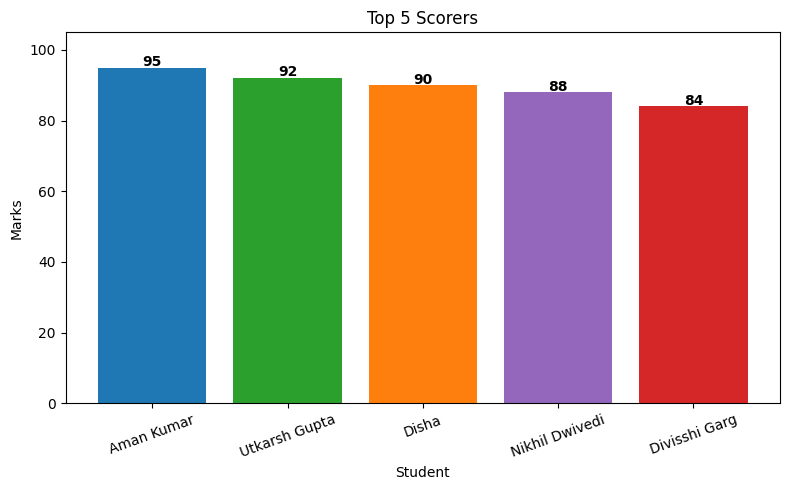

In [ ]:
def plot_top5(sl):
    sort_by_marks(sl)
    top = sl.to_nodes()[:5]
    names = [s.name for s in top]
    marks = [s.marks for s in top]

    plt.figure(figsize=(8, 5))
    bars = plt.bar(names, marks, color=["#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd", "#d62728"])
    for b, m in zip(bars, marks):
        plt.text(b.get_x() + b.get_width()/2, m + 0.5, str(m), ha="center", fontweight="bold")
    plt.title("Top 5 Scorers")
    plt.xlabel("Student")
    plt.ylabel("Marks")
    plt.ylim(0, 105)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

plot_top5(students)